# 장보기 대시보드를 위한 소매가격 분석

**어디에서 살까? 지난주보다 싸졌을까? 한 곳에서 세 가지를 사면 얼마일까?**

참고 화면인 「오늘 뭐 사지?」의 가격 검색과 장보기 기능에 사용할 수 있는 지표를 살펴봤다. 한국농수산식품유통공사의 2026년 10월 26일부터 11월 24일까지의 소매가격 132,123건 중 시장 코드가 있는 115,312건을 사용했다. 지역과 조사처 가격은 가장 최근 조사일인 **11월 24일** 기준이다.

품종, 등급, 단위와 수량이 같은 가격끼리 비교했다. 다섯 가지 예시는 모두 상품 등급이다. 평균은 조사처별 가격을 더하고 조사처 수로 나눈 값이다.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import StrMethodFormatter
import pandas as pd

path = Path("sample_data/한국농수산식품유통공사_기간별_소매가격_정보_조회.csv")
raw = pd.read_csv(path, dtype=str, encoding="utf-8-sig")
markets = raw.dropna(subset=["mrkt_cd"]).copy()
markets["날짜"] = pd.to_datetime(markets["exmn_ymd"], format="%Y%m%d")
markets["가격"] = pd.to_numeric(markets["exmn_dd_prc"])
latest_date = markets["날짜"].max()
previous_date = latest_date - pd.Timedelta(days=7)

spec = ["item_cd", "vrty_cd", "grd_cd", "unit_sz", "unit"]
products = pd.DataFrame([
    ("245", "00", "04", "1", "kg", "양파 1kg"),
    ("246", "00", "04", "1", "kg", "대파 1kg"),
    ("224", "01", "04", "1", "개", "애호박 1개"),
    ("411", "05", "04", "10", "개", "후지 사과 10개"),
    ("226", "00", "04", "500", "g", "설향 딸기 500g"),
], columns=spec + ["상품"])
prices = markets.merge(products, on=spec, validate="many_to_one")
latest = prices[prices["날짜"].eq(latest_date)]
onion = prices[prices["상품"].eq("양파 1kg")]

fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ("Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "NanumGothic"):
    if font in fonts:
        plt.rcParams["font.family"] = [font, "DejaVu Sans"]
        break
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.unicode_minus": False, "figure.dpi": 140, "font.size": 11,
})

def draw_bars(values, title, unit="원"):
    _, ax = plt.subplots(figsize=(8, 1.5 + .35 * len(values)), layout="constrained")
    colors = ["#b24b38" if value < 0 else "#236d62" for value in values]
    bars = ax.barh(values.index, values, color=colors)
    ax.invert_yaxis()
    ax.set(title=title, xlabel=f"가격 ({unit})" if unit == "원" else "지난주 대비 가격 변화 (%)")
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    if unit == "원":
        labels = [f"{value:,.0f}원" for value in values]
        ax.set_xlim(0, values.max() * 1.16)
    else:
        labels = [
            f"{abs(value):.1f}% {'하락' if value < 0 else '상승'}" if value else "변화 없음"
            for value in values
        ]
        ax.axvline(0, color="#6d7075", linewidth=.8)
        ax.margins(x=.27)
    ax.bar_label(bars, labels=labels, padding=5)
    ax.grid(axis="x", alpha=.18)
    ax.set_axisbelow(True)
    plt.show()

## 1. 같은 상품의 가격은 지역마다 얼마나 다를까?

11월 24일에 양파 1kg을 조사한 곳이 3곳 이상인 지역만 비교했다.

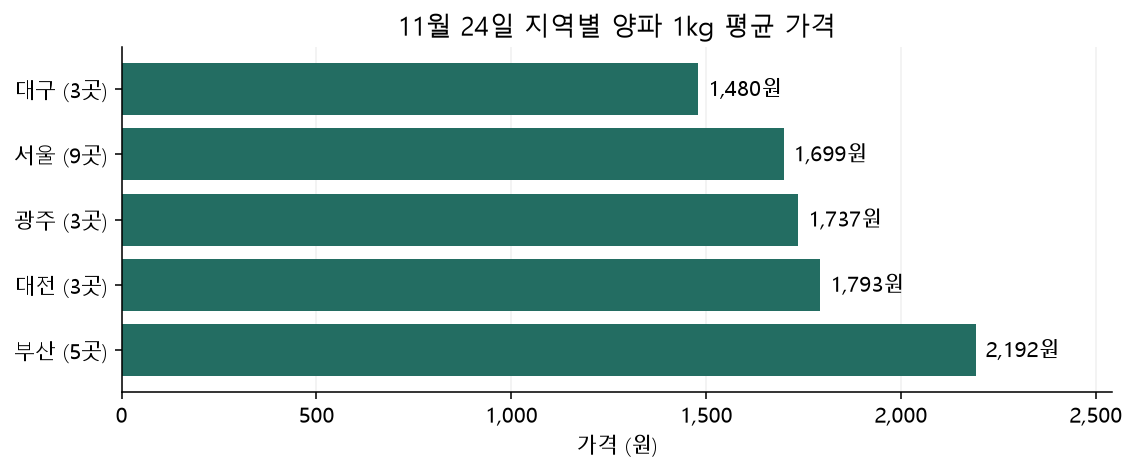

In [2]:
region = latest[latest["상품"].eq("양파 1kg")].groupby("sgg_nm")["가격"].agg(["mean", "size"])
region = region[region["size"].ge(3)].sort_values("mean")
region_labels = [f"{name} ({count}곳)" for name, count in region["size"].items()]
draw_bars(region["mean"].set_axis(region_labels), "11월 24일 지역별 양파 1kg 평균 가격")

대구는 평균 **1,480원**, 부산은 **2,192원**이었다. 두 지역의 차이는 **712원**이다. 대구는 3곳, 부산은 5곳의 가격을 사용했다.

**화면에 표시할 내용**  
지역 평균 옆에 조사처 수를 표시한다. 같은 양파라도 어느 시장을 조사했는지에 따라 지역 평균이 달라질 수 있다.

## 2. 같은 지역에서도 마트나 시장에 따라 가격이 다를까?

11월 24일 서울에서 같은 대파 1kg을 조사한 9곳을 비교했다. 원본에서 영문으로 표시한 유통 조사처는 읽기 쉽게 이름을 줄였다. 원본에 비슷한 이름이 있는 조사처는 코드 끝 세 자리인 411을 사용했다.

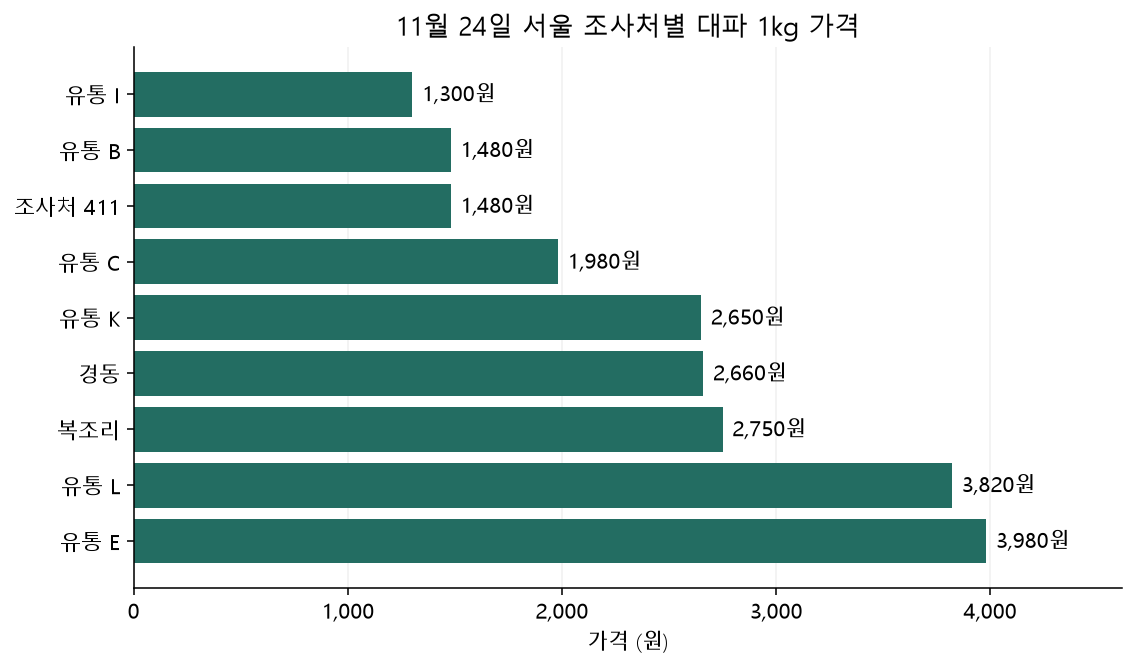

In [3]:
seoul = latest[latest["sgg_nm"].eq("서울")]
seoul_prices = seoul.pivot(index="mrkt_cd", columns="상품", values="가격")
store_names = {
    "0110212": "경동", "0110213": "복조리",
    "0110403": "유통 C", "0110406": "유통 B", "0110407": "유통 K",
    "0110408": "유통 E", "0110409": "유통 I", "0110410": "유통 L", "0110411": "조사처 411",
}
green_onion = seoul_prices["대파 1kg"].dropna().sort_values()
draw_bars(green_onion.rename(index=store_names), "11월 24일 서울 조사처별 대파 1kg 가격")

서울의 대파 1kg은 **1,300원부터 3,980원**까지였다. 같은 날과 같은 규격에서 **2,680원** 차이가 났다.

**화면에 표시할 내용**  
상품 가격 범위와 조사 날짜를 보여 준다. 유통 조사처의 실제 지점 이름과 주소는 이 CSV에서 확인할 수 없다. 특정 매장을 안내하려면 지점 정보가 필요하다.

## 3. 지난주 같은 요일보다 싸진 상품은 무엇일까?

11월 17일과 24일 두 화요일에 모두 조사된 곳만 상품별로 남겼다. 두 날짜의 조사 평균을 비교했다.

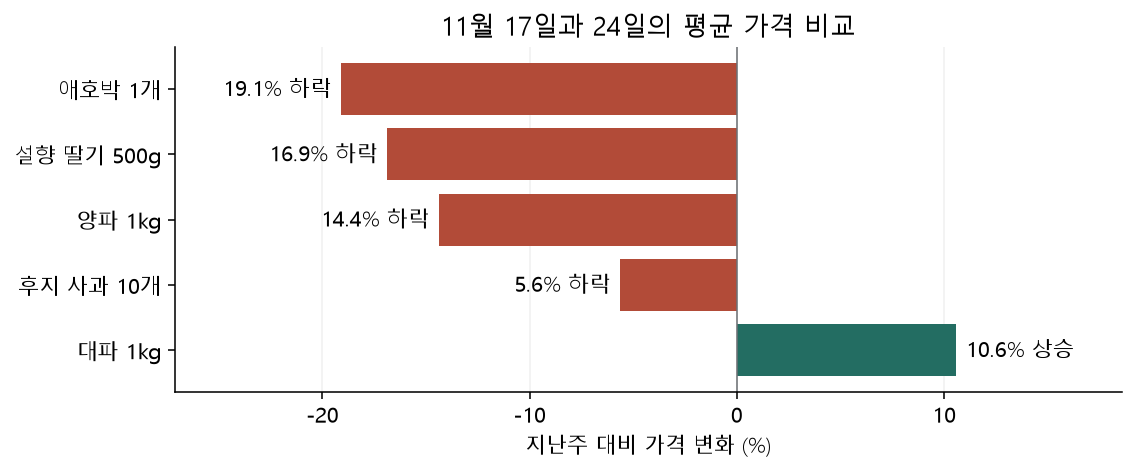

상품,11월 17일 (원),11월 24일 (원),변화율 (%),조사처 수
애호박 1개,"1,849","1,495",-19.1%,50
설향 딸기 500g,"19,437","16,157",-16.9%,35
양파 1kg,"2,080","1,781",-14.4%,50
후지 사과 10개,"18,383","17,346",-5.6%,46
대파 1kg,"2,249","2,487",10.6%,50


In [4]:
dates = [previous_date, latest_date]
two_days = prices[prices["날짜"].isin(dates)].pivot(
    index=["상품", "sgg_cd", "mrkt_cd"], columns="날짜", values="가격"
).dropna()
weekly = two_days.groupby("상품").mean()
weekly.columns = ["지난주 가격", "최근 가격"]
weekly["변화율"] = (weekly["최근 가격"] / weekly["지난주 가격"] - 1) * 100
weekly["조사처 수"] = two_days.groupby("상품").size()
weekly = weekly.sort_values("변화율")
draw_bars(weekly["변화율"], "11월 17일과 24일의 평균 가격 비교", unit="%")
weekly_view = weekly.reset_index().rename(columns={
    "지난주 가격": "11월 17일 (원)", "최근 가격": "11월 24일 (원)", "변화율": "변화율 (%)",
})
weekly_view.style.format({
    "11월 17일 (원)": "{:,.0f}", "11월 24일 (원)": "{:,.0f}", "변화율 (%)": "{:.1f}%",
}).hide(axis="index")

선택한 다섯 상품 중 네 상품이 싸졌다. **애호박은 19.1%, 설향 딸기는 16.9%, 양파는 14.4%** 내렸다. 대파는 **10.6% 상승**을 기록했다.

**화면에 표시할 내용**  
가격 옆에 “지난주 같은 요일보다 14.4% 저렴”과 같이 기준 날짜가 있는 문구를 붙일 수 있다. 비교일에 같은 조사처의 기록이 없으면 해당 조사처는 지난주 비교에서 뺀다.

## 4. 최근 조사 가격은 이 한 달의 평균과 비교해 어떨까?

양파 1kg은 22개 조사일에 모두 기록된 50곳으로 일별 평균을 구했다. 점선은 22개 조사일의 평균이다.

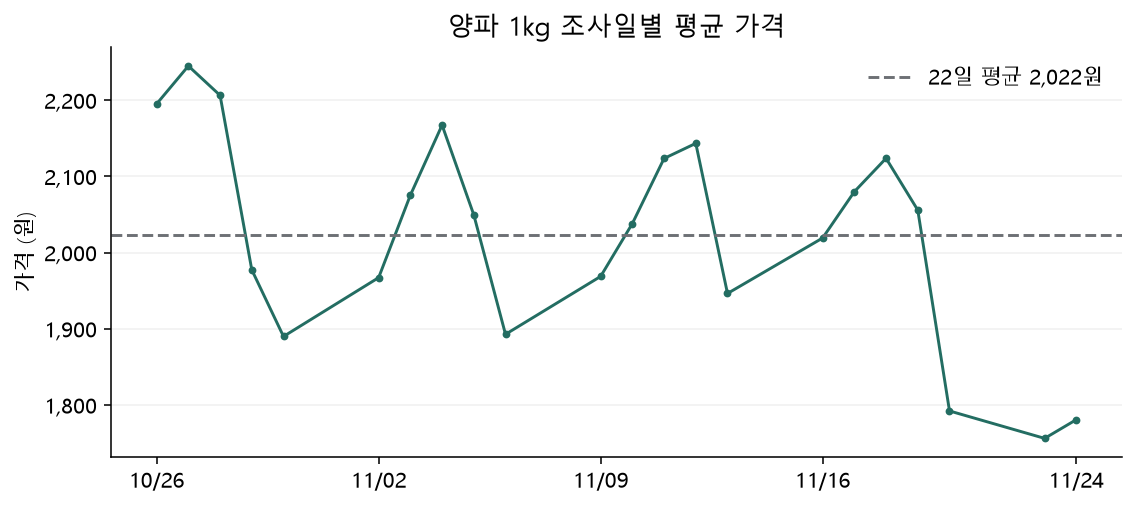

In [5]:
onion_daily = onion.pivot(
    index="날짜", columns=["sgg_cd", "mrkt_cd"], values="가격"
).dropna(axis="columns").mean(axis="columns")
recent_average = onion_daily.mean()

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(onion_daily.index, onion_daily, color="#236d62", marker="o", markersize=3)
ax.axhline(recent_average, color="#6d7075", linestyle="--", label=f"22일 평균 {recent_average:,.0f}원")
ax.set(title="양파 1kg 조사일별 평균 가격", ylabel="가격 (원)")
ax.set_xticks(onion_daily.index[[0, 5, 10, 15, -1]])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=.18)
ax.legend(frameon=False)
plt.show()

11월 24일 평균은 **1,781원**으로 22개 조사일 평균인 **2,022원**보다 241원 낮았다. 11월 20일부터 11월 24일까지 관측한 세 날짜에서 1,700원대가 이어졌다.

**화면에 표시할 내용**  
짧은 이력에서는 “10월 26일부터 11월 24일까지 조사한 날의 평균”과 같이 기준 기간을 명시한다. 참고 대시보드의 공식 평년 대비 지표를 쓰려면 별도의 평년 자료가 필요하다.

## 5. 한 곳에서 장바구니를 채우면 얼마일까?

서울에서 양파 1kg, 대파 1kg, 애호박 1개를 같은 날 모두 조사한 곳의 가격을 더했다.

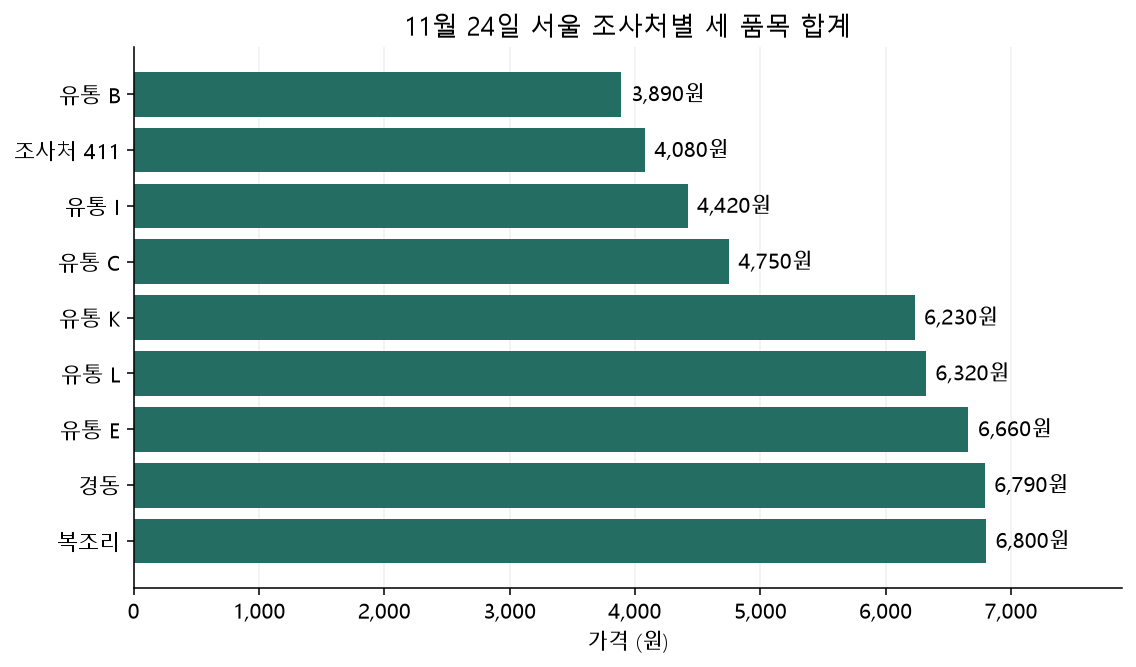

조사처,양파 1kg,대파 1kg,애호박 1개,합계
유통 B,"1,220원","1,480원","1,190원","3,890원"
조사처 411,"1,220원","1,480원","1,380원","4,080원"
유통 I,"1,860원","1,300원","1,260원","4,420원"
유통 C,"1,490원","1,980원","1,280원","4,750원"
유통 K,"1,990원","2,650원","1,590원","6,230원"
유통 L,"1,320원","3,820원","1,180원","6,320원"
유통 E,"1,490원","3,980원","1,190원","6,660원"
경동,"2,400원","2,660원","1,730원","6,790원"
복조리,"2,300원","2,750원","1,750원","6,800원"


In [6]:
basket_items = ["양파 1kg", "대파 1kg", "애호박 1개"]
basket = seoul_prices[basket_items].dropna().copy()
basket["합계"] = basket[basket_items].sum(axis="columns")
basket = basket.sort_values("합계").rename(index=store_names).astype(int)
draw_bars(basket["합계"], "11월 24일 서울 조사처별 세 품목 합계")
basket_view = basket.rename_axis(index="조사처", columns=None).reset_index()
basket_view.style.format("{:,}원", subset=basket_items + ["합계"]).hide(axis="index")

세 품목 합계는 유통 B가 **3,890원**, 복조리가 **6,800원**이었다. 차이는 **2,910원**이다. 대파만 보면 유통 I가 가장 저렴했고, 세 품목 합계는 유통 B가 가장 낮았다.

**화면에 표시할 내용**  
선택한 품목을 같은 날 모두 조사한 곳만 합계 비교에 사용한다. 여러 품목을 살 때는 상품 하나의 최저가와 장바구니 합계를 함께 볼 수 있다.

## 6. 어느 지역까지 가격 비교를 제공할 수 있을까?

11월 24일에 시장 코드가 있는 기록에서 지역별 조사처 수를 셌다. 품목별로는 실제 가격 기록이 있는 조사처 수가 더 적을 수 있다.

In [7]:
market_counts = markets[markets["날짜"].eq(latest_date)].groupby("sgg_nm")["mrkt_cd"].nunique()
pd.Series({
    "1곳": market_counts.eq(1).sum(),
    "2곳": market_counts.eq(2).sum(),
    "3곳 이상": market_counts.ge(3).sum(),
}, name="지역 수").rename_axis("하루 조사처 수").to_frame()

,지역 수
하루 조사처 수,
1곳,7
2곳,10
3곳 이상,5


**22개 지역 중 7개 지역은 조사처가 한 곳뿐이었다.** 3곳 이상인 지역은 5개다. 시장 코드가 있는 가격은 표본의 평일 22일에 기록됐다. 시장 코드가 없는 축산물 16,811건은 지역이나 전국 단위로 기록돼 이번 조사처 비교에서 제외했다.

**화면에 표시할 내용**  
조사처가 한 곳이면 “조사처 1곳의 가격”을 표시한다. 주말이나 기록이 없는 날에는 마지막 조사 날짜를 함께 보여 준다.

## 데이터와 실행 방법

출처는 프로젝트의 `sample_data/한국농수산식품유통공사_기간별_소매가격_정보_조회.csv`다. 가격은 원본 조사 가격인 `exmn_dd_prc`를 사용했다. 시각화의 상품 다섯 가지는 장보기 화면 예시로 골랐다.

프로젝트 루트에서 `pandas`와 `matplotlib`이 설치된 Python 커널로 셀을 순서대로 실행하면 된다. 한글 차트에는 운영체제의 한글 글꼴을 사용한다.